In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
diabetes = load_diabetes()

X = diabetes.data
y = diabetes.target

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("First 10 target values:", y[:10])

Dataset shape: (442, 10)
Number of features: 10
First 10 target values: [151.  75. 141. 206. 135.  97. 138.  63. 110. 310.]


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 353
Testing samples: 89


In [4]:
model = DecisionTreeRegressor(
    criterion="squared_error",
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

print("Decision Tree Regression model trained successfully.")

Decision Tree Regression model trained successfully.


In [5]:
y_pred = model.predict(X_test)

print("Actual values:   ", y_test[:10])
print("Predicted values:", np.round(y_pred[:10], 2))

Actual values:    [219.  70. 202. 230. 111.  84. 242. 272.  94.  96.]
Predicted values: [175.33 182.77 175.33 241.2  121.86  90.33 203.5  241.2  134.81 182.77]


In [6]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Mean Absolute Error (MAE): 47.05
Mean Squared Error (MSE): 3568.97
Root Mean Squared Error (RMSE): 59.74
R2 Score: 0.3264


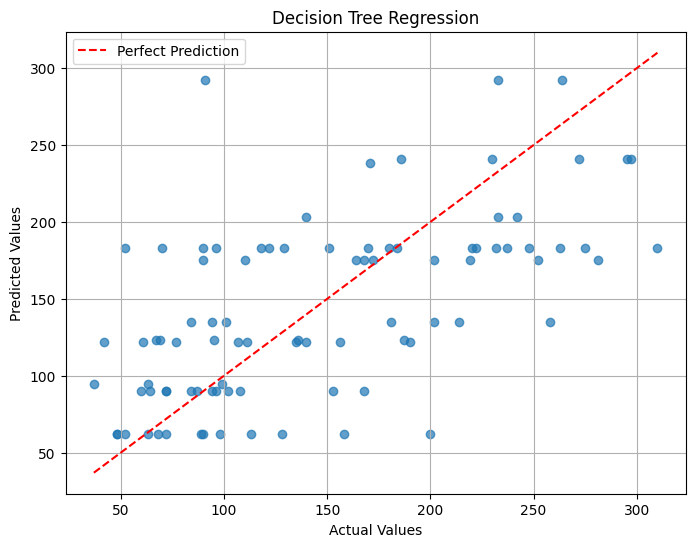

In [7]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Decision Tree Regression")
plt.legend()
plt.grid(True)
plt.show()

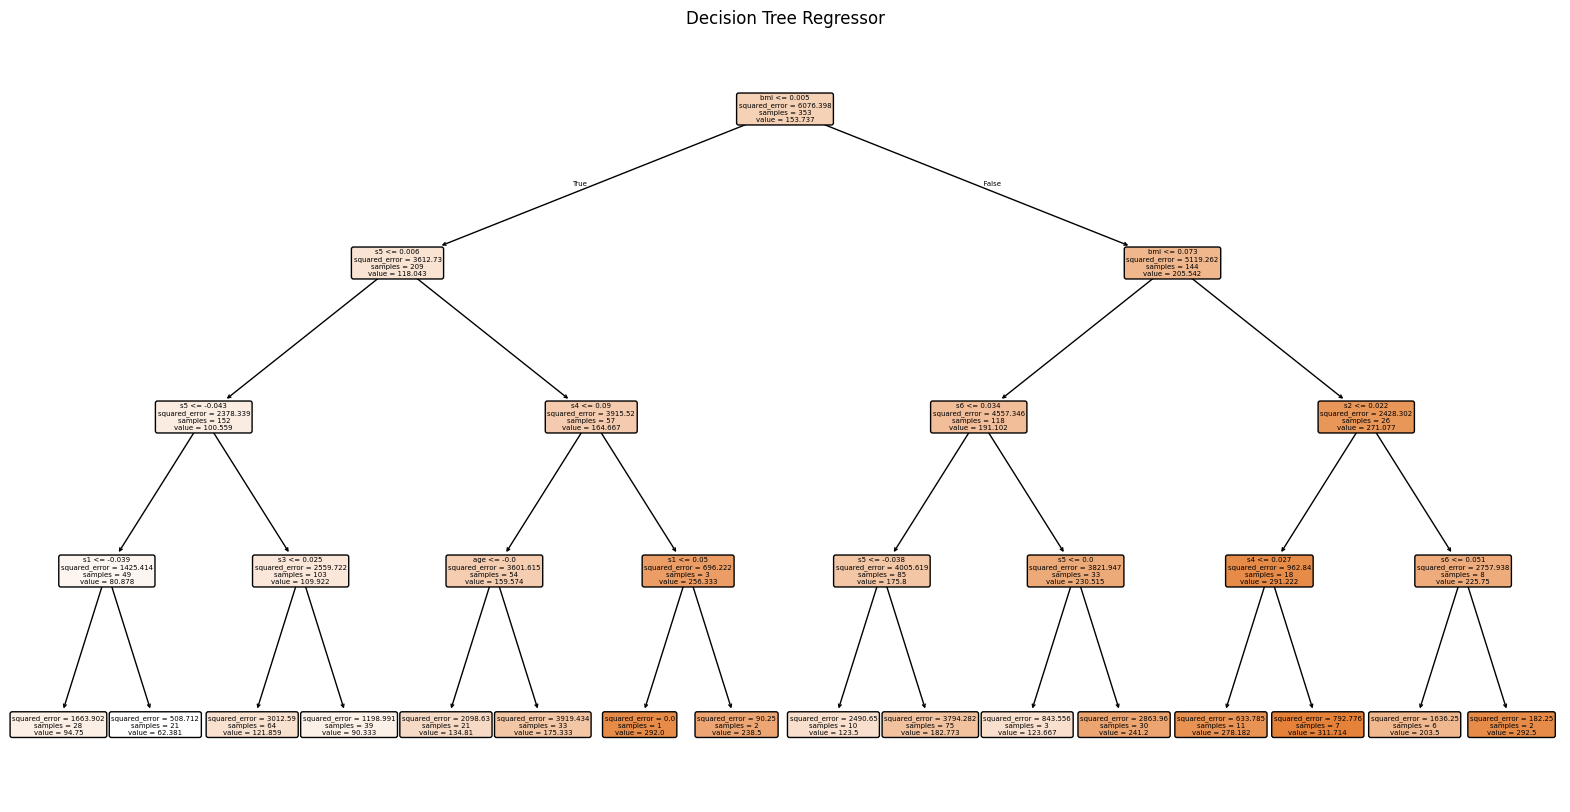

In [8]:
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=diabetes.feature_names,
    filled=True,
    rounded=True
)

plt.title("Decision Tree Regressor")
plt.show()